In [28]:
%load_ext autoreload
%autoreload 2

%reload_ext autoreload

from pathlib import Path
import sys
path = str(Path(Path('File.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

import numpy as np
import matplotlib as mlab
import matplotlib.pyplot as plt
import xarray as xr
import os as os
import glob
import matplotlib.gridspec as gridspec
from analysis_tools import getobjdata

from tools.cbook import pickle2Obj, interp_z, compute_thetae
from tools.FV3_tools import read_solo_fields, read_solo_w, read_solo_w2
from tools.CM1_tools import read_cm1_fields

import scipy.ndimage as ndimage
import matplotlib.colors as mcolors

from colormaps import radar_colormap

from timeit import default_timer as timer

from pathlib import Path
import sys
path = str(Path(Path('File.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

from tools.cbook import pickle2Obj

_nthreads = 10

zlevels = 10.0 + 250.*np.arange(61)

velocity_unicode = "m s\u207B\u00B9"
massflux_unicode = "kg s\u207B\u00B9"

# draw filled contours.
clevs = [0, 1, 2.5, 5, 7.5, 10, 15, 20, 30, 40, 50, 70, 100, 150, 200, 250, 300, 400, 500, 600, 750]

cmap_data = [(1.0, 1.0, 1.0),
         (0.3137255012989044, 0.8156862854957581, 0.8156862854957581),
         (0.0, 1.0, 1.0),
         (0.0, 0.8784313797950745, 0.501960813999176),
         (0.0, 0.7529411911964417, 0.0),
         (0.501960813999176, 0.8784313797950745, 0.0),
         (1.0, 1.0, 0.0),
         (1.0, 0.6274510025978088, 0.0),
         (1.0, 0.0, 0.0),
         (1.0, 0.125490203499794, 0.501960813999176),
         (0.9411764740943909, 0.250980406999588, 1.0),
         (0.501960813999176, 0.125490203499794, 1.0),
         (0.250980406999588, 0.250980406999588, 1.0),
         (0.125490203499794, 0.125490203499794, 0.501960813999176),
         (0.125490203499794, 0.125490203499794, 0.125490203499794),
         (0.501960813999176, 0.501960813999176, 0.501960813999176),
         (0.8784313797950745, 0.8784313797950745, 0.8784313797950745),
         (0.9333333373069763, 0.8313725590705872, 0.7372549176216125),
         (0.8549019694328308, 0.6509804129600525, 0.47058823704719543),
         (0.6274510025978088, 0.42352941632270813, 0.23529411852359772),
         (0.4000000059604645, 0.20000000298023224, 0.0)]
cmap = mcolors.ListedColormap(cmap_data, 'precipitation')
norm = mcolors.BoundaryNorm(clevs, cmap.N)


savePlots = True

models = {}
# start = timer()
# cm1  = read_cm1_fields('/work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S12', vars = ['w'], zinterp=zlevels, ret_ds=False)
# solo = read_solo_fields('/work/wicker/climate_runs/FV3_Solo/squall/euler/3km/QV16/S18', vars = ['w'], zinterp=zlevels, ret_ds=False)

# end = timer()

# print(f"Time to read file: {end - start:.2f} sec")

# plt.contourf(cm1['w'][15,:,128,:]);
# plt.plot()
# # plt.contourf(solo['w'][15,:,128,:]);
# print(cm1['w'].shape)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
#----------------------------- READ DATA IN ---------------

paths = {}
paths['cm1_QV16_S18']  = '/work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S18'
paths['solo_QV16_S18'] = '/work/wicker/climate_runs/FV3_Solo/squall/euler/3km/QV16/S18'
paths['cm1_QV13_S06']  = '/work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV13/S18'
paths['solo_QV13_S06'] = '/work/wicker/climate_runs/FV3_Solo/squall/euler/3km/QV13/S18'

# paths = {}
# paths['cm1']  = '/work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S18'
# paths['solo'] = '/work/wicker/climate_runs/FV3_Solo/squall/euler/3km/QV16/S18'

models = {}

for key in paths:
    print("\n Reading: ",key)
    if key[0:3] == 'cm1':
        models[key] = ( read_cm1_fields(paths[key], vars = ['w','rwqv'], zinterp=zlevels, ret_ds=False) )
    if key[0:4] == 'solo':
        models[key] = ( read_solo_fields(paths[key], vars = ['w','rwqv'], zinterp=zlevels, ret_ds=False) )


 Reading:  cm1_QV16_S18
------------------------------------------------------------------------------------------------------------------------

 Now reading... /work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S18/cm1out.nc

 Time for xarray to load:  /work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S18/cm1out.nc: 0.03 sec 

 Completed setup for:  /work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S18/cm1out.nc --> time to initialize variables: 2.62 sec 

 Completed reading in:  /work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S18/cm1out.nc --> time to process variables: 1.75 sec 

 Interpolating fields to single column z-grid: /work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S18/cm1out.nc 

 Interpolated completed, Total CPU:  /work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S18: 0.43 sec 

 Total time for processing file:  /work/wicker/climate_runs/cm1r20.3/run/squall/3km/QV16/S18: --> 4.83 sec 

----------------------------------------------------

In [111]:
# draw filled contours.
clevs = np.asarray([2.5, 5, 7.5, 10, 15, 20, 30])
#clevs = np.asarray([0, 1, 2.5, 5, 7.5, 10, 15, 20, 30, 40, 50, 70, 100, 150, 200, 250])

from tools.plotbook import label_panels

cmap = 'OrRd'
# norm = mcolors.BoundaryNorm(0.5*clevs, cmap.N)

def plot_hovmoller_w(models, key, label, label2=None, clevels=[10,30,50], ylim = None, ax=None):
    
    # Arbitrary weights
    # weights = np.array([[0, 0, 1, 0, 0],
    #                     [0, 2, 4, 2, 0],
    #                     [1, 4, 8, 4, 1],
    #                     [0, 2, 4, 2, 0],
    #                     [0, 0, 1, 0, 0]], dtype=np.float)
    # weights = weights / np.sum(weights[:])
    
    # fmean = ndimage.filters.convolve(models[key][label]['accum_prec'].mean(axis=1),  weights, mode='constant')
    # fmax  = ndimage.filters.convolve(models[key][label]['accum_prec'].max(axis=1),  weights, mode='constant')
    
    # first, compute the increments in time of precip
    
    fld = models[key]['w']
    fld = fld.max(axis=1)
    
    # fld      = models[key][label]['accum_prec']
    fld_mask = np.where(fld > 1.0, fld, np.nan)
    fmean    = np.nanmax(fld, axis=1)
    fsum     = np.nansum(fld_mask)
    fmax     = fld.max()

    if key == 'solo':
        time = 15. + 15*np.arange(models[key]['w'].shape[0])
    else:
        time = 15*np.arange(models[key]['w'].shape[0])
        
    xg = 3*np.arange(models[key]['w'].shape[2])
    
    cs = ax.contourf(xg, time[::-1], fmean[::-1], clevs, cmap=plt.cm.get_cmap(cmap), vmax=30, vmin=1)
    
    # ax.contour(xg, time[::-1], fmean[::-1], clevels=[20,], alpha=0.5, colors=['k',])
    ax.set_ylabel('Time (min)', fontsize=12)
    ax.set_xlabel('X (km)', fontsize=12)
    ax.set_title(f"{label2} \n Maximum W: {np.nanmax(fmax):.0f} {velocity_unicode}", fontsize=10)
        
    ax.set_xlim(0.0, 600)
    if ylim:
        ax.set_ylim(ylim,0.0)
    else:
        ax.set_ylim(time[-1],0.0)
    
    return cs

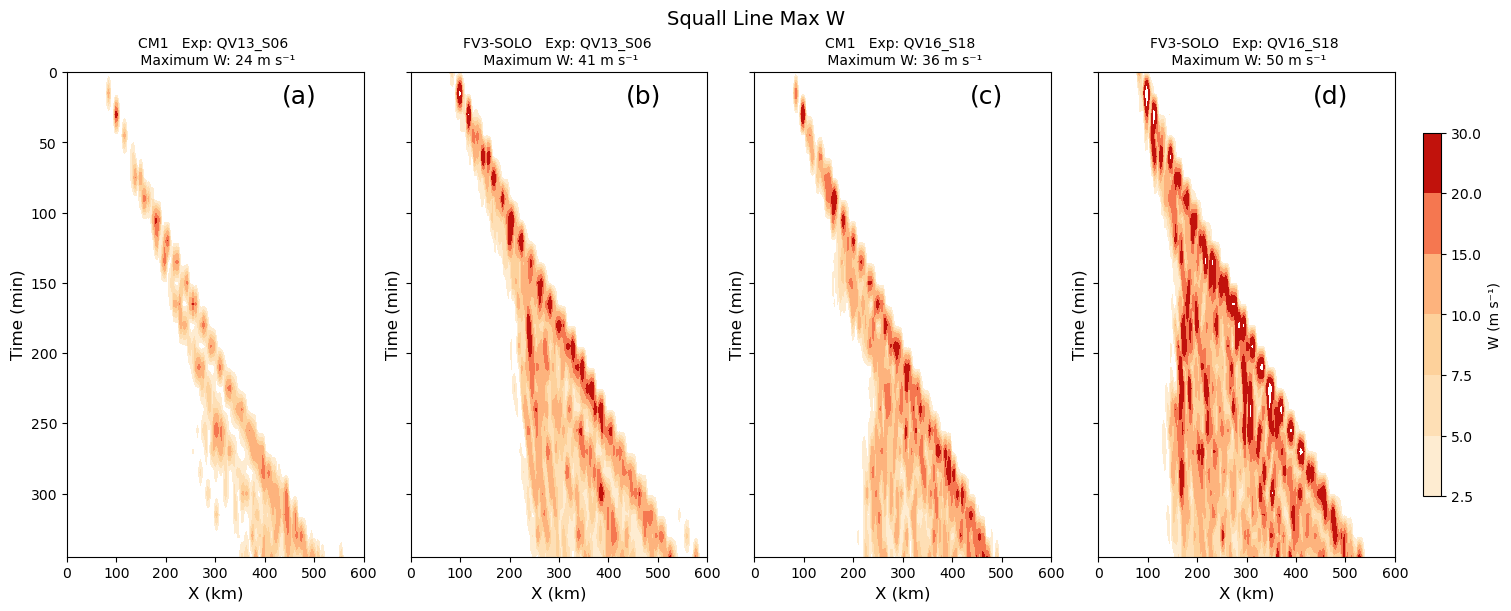

In [118]:
labels = ['QV13_S06', 'QV16_S18']

n = -1

fig, ax = plt.subplots(1,4, constrained_layout=True, sharey=True, figsize=(15,6))

for label in labels:

        n = n + 1
        cm1_label = 'cm1_'+label
        solo_label = 'solo_'+label        
        cs = plot_hovmoller_w(models, cm1_label, label, label2=f'CM1   Exp: {label}', ax=ax[2*n])
        cs = plot_hovmoller_w(models, solo_label, label, label2=f'FV3-SOLO   Exp: {label}', ax=ax[1+2*n]) 
        
cbar = fig.colorbar(cs, ax=ax[3], shrink=0.75, location='right')

cbar.set_label(f'W ({velocity_unicode})', fontsize=10)

plt.suptitle("Squall Line Max W", fontsize=14)

label_panels(ax, ['(a)', '(b)', '(c)', '(d)'], adjust_loc=[0.7, 0.0], fontsize=18);
        
plt.savefig("/work/wicker/CAM_analysis_tools/ideal_cases/Analysis/plots/Hovmoller_W_4Panel.pdf")
plt.savefig("/work/wicker/CAM_analysis_tools/ideal_cases/Analysis/plots/Hovmoller_W_4Panel.png")